# Walls of the domain

By default the size of the domain plays no role: elements move freely. With `domain_walls` switched on, the
faces of the domain (the bounding box of the mesh) keep the elements inside.

**The wall force.** An element at the distance $h$ from a wall is pushed away from it as if it faced its own
mirror image behind the wall, at the distance $2h$, through the pair potential $V$:

$$F_\mathrm{wall}(h) = \begin{cases} F_\mathrm{pair}(2h) & h < r_\mathrm{eq}/2 \\ 0 & h \ge r_\mathrm{eq}/2 \end{cases}
\qquad U_\mathrm{wall}(h) = \tfrac12\left[V(2h) - V(r_\mathrm{eq})\right]$$

- It starts where an element drawn as a sphere of radius $r_\mathrm{eq}/2$ touches the wall.
- Only the repulsive part is used. A wall never attracts: there is no adhesion to it.
- It is normal to the wall. In a 2D simulation there is no wall along $z$.
- A wall is as hard as another cell of the element's own type: its well depth is the `inter_well_depth` of
  the cell type, its reach half the type's equilibrium distance. The wall adds no parameter of its own.

**The hard stop.** The repulsion of this potential does not grow without bound: it falls back to zero when two
elements coincide. A push stronger than the highest wall force would therefore carry an element through. As a
guard, the solver puts any element that ends a step outside the domain back on the face it crossed, and
counts how often that happened (`wall_stops`).

The data comes from the C++ solver through the `domain_walls` example:

```bash
E=build/gcc-debug/mechanics/micromechanics/examples/mechanics.micromechanics.domain_walls
D=mechanics/micromechanics/docs/notebooks/data
$E force > $D/wall_force.csv
for v in 0.2 0.6; do $E stall $v > $D/wall_stall_$v.csv; done
```

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})


def load(name):
    file = Path("data") / name
    header = file.read_text().splitlines()[0].lstrip("# ").split()
    params = dict(item.split("=") for item in header)
    params = {key: (value if key == "experiment" else float(value)) for key, value in params.items()}
    return params, np.genfromtxt(file, delimiter=",", names=True, skip_header=1)

## The force of a wall

strongest wall force 38.8 at h = 0.170; energy to reach the wall 10.21 (well depth 0.5)


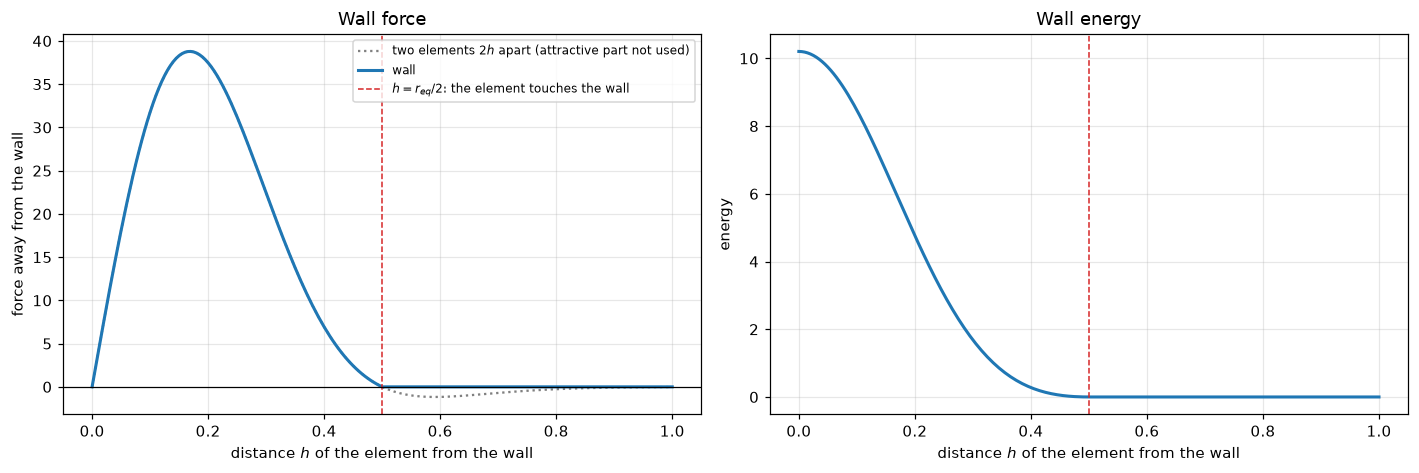

In [2]:
params, table = load("wall_force.csv")
h, force, energy, pair = table["distance"], table["wall_force"], table["wall_energy"], table["pair_force_at_twice_the_distance"]
reach = 0.5 * params["equilibrium_distance"]

fig, (ax_force, ax_energy) = plt.subplots(1, 2, figsize=(13, 4.4))
ax_force.plot(h, pair, color="gray", linestyle=":", label="two elements $2h$ apart (attractive part not used)")
ax_force.plot(h, force, linewidth=2, label="wall")
ax_force.axvline(reach, color="tab:red", linestyle="--", linewidth=1, label="$h = r_{eq}/2$: the element touches the wall")
ax_force.axhline(0, color="black", linewidth=0.8)
ax_force.set(xlabel="distance $h$ of the element from the wall", ylabel="force away from the wall", title="Wall force")
ax_force.legend(fontsize=8)

ax_energy.plot(h, energy, linewidth=2)
ax_energy.axvline(reach, color="tab:red", linestyle="--", linewidth=1)
ax_energy.set(xlabel="distance $h$ of the element from the wall", ylabel="energy", title="Wall energy")
fig.tight_layout()

# never attractive, zero beyond the reach, and minus the derivative of the energy
assert np.all(force >= 0) and np.all(force[h >= reach] == 0)
inside = (h > 0.02) & (h < reach - 0.02)
assert np.allclose(force[inside], -np.gradient(energy, h)[inside], rtol=0.02, atol=0.05)

strongest = force.max()
print(f"strongest wall force {strongest:.1f} at h = {h[force.argmax()]:.3f}; "
      f"energy to reach the wall {energy[0]:.2f} (well depth {params['wall_well_depth']:g})")

The highest force the wall can exert on one element is printed above. Anything that pushes a single element
harder than that goes through the soft wall and meets the hard stop. For comparison, a motile cell pushes
each of its elements with `drag_coefficient × migration_speed`, which is below 1 in all the examples here.

Thermal noise is different: a kick is not a force, and a kick much larger than the reach of the wall jumps
over it. With a thermal energy $D\eta$ well below the energy needed to reach the wall (printed above), the
soft wall alone holds; the unit tests check both regimes.

## A cell crawling into a wall

A motile cell of 37 elements in 2D heads straight for a wall. It arrives at its migration speed, is slowed
down as its leading elements enter the reach of the wall, and stalls. Its pressure rises from zero to the
value at which the wall holds its whole traction.

speed 0.2: nearest element ends 0.396 from the wall, centre 3.08; pressure 0.3096, estimate from the traction 0.3553
speed 0.6: nearest element ends 0.385 from the wall, centre 2.31; pressure 0.6625, estimate from the traction 0.7993


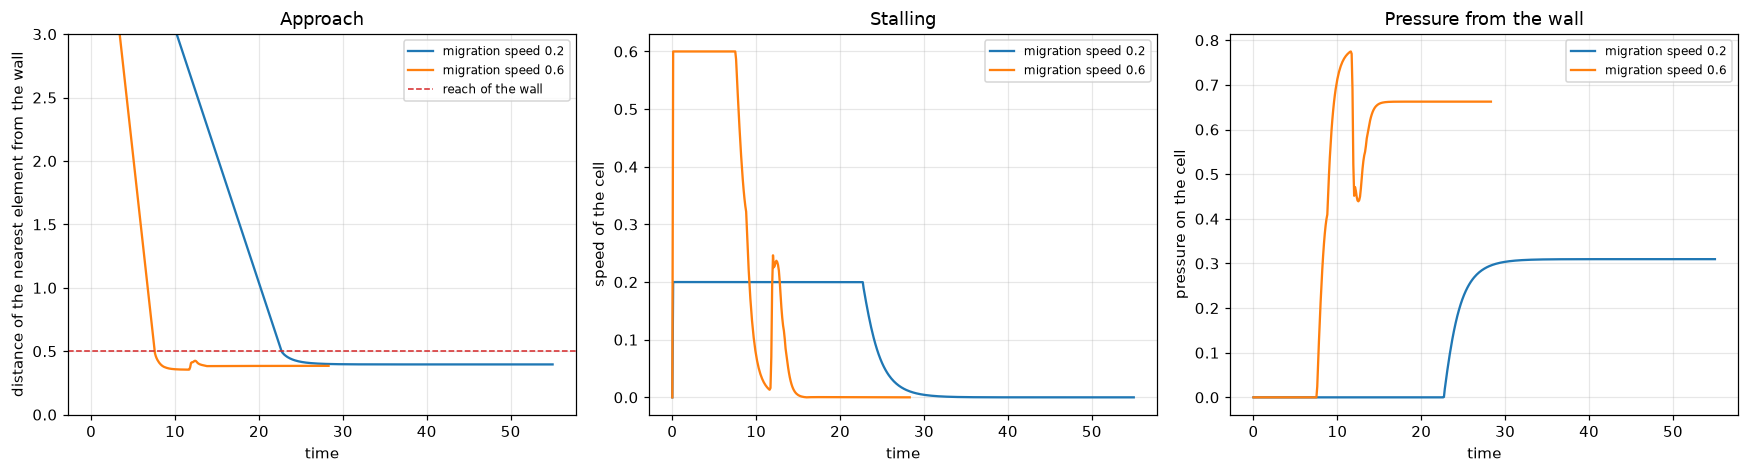

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))

for speed in ("0.2", "0.6"):
    params, table = load(f"wall_stall_{speed}.csv")
    time = table["time"]
    label = f"migration speed {speed}"
    axes[0].plot(time, table["nearest_element_to_wall"], label=label)
    axes[1].plot(time, table["speed"], label=label)
    axes[2].plot(time, table["pressure"], label=label)

    # the cell arrives at its migration speed, stops, and no element goes beyond the wall
    v = params["migration_speed"]
    assert abs(table["speed"][1] / v - 1) < 0.02
    assert table["speed"][-1] < 0.01 * v, f"speed {speed}: still moving at {table['speed'][-1]:.4f}"
    assert table["nearest_element_to_wall"].min() > 0
    assert table["pressure"][0] == 0 and table["pressure"][-1] > 0

    # the wall holds the traction N * drag * v, applied about the centre-to-wall distance from the centre
    n, drag = params["elements_per_cell"], params["drag_coefficient"]
    volume = n * np.sqrt(3) / 2 * params["equilibrium_distance"] ** 2
    estimate = n * drag * v * table["distance_to_wall"][-1] / (2 * volume)
    print(f"speed {speed}: nearest element ends {table['nearest_element_to_wall'][-1]:.3f} from the wall, centre "
          f"{table['distance_to_wall'][-1]:.2f}; pressure {table['pressure'][-1]:.4f}, estimate from the traction {estimate:.4f}")
    assert abs(table["pressure"][-1] / estimate - 1) < 0.3

axes[0].axhline(0.5, color="tab:red", linestyle="--", linewidth=1, label="reach of the wall")
axes[0].set(xlabel="time", ylabel="distance of the nearest element from the wall", ylim=(0, 3), title="Approach")
axes[1].set(xlabel="time", ylabel="speed of the cell", title="Stalling")
axes[2].set(xlabel="time", ylabel="pressure on the cell", title="Pressure from the wall")
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()

## Reading the result

- **The wall is a force, not a rule.** It enters the equation of motion like any other force, so velocities
  stay consistent, energy is accounted for, and the wall shows up in the pressure of a cell that leans on it.
- **A cell pressed against a wall is compressed** by an amount that matches its traction times the distance
  from its centre to the wall.
- **Cells do not stick to walls.** A cell that turns away leaves freely.

### Caveats

- **Off by default.** Without `domain_walls` nothing confines the cells, and results do not depend on the
  size of the domain.
- **The soft wall can be overpowered**, by a force above the value printed in the first section or by strong
  noise. The hard stop then keeps the element inside, but an element put back on the wall did not follow the
  equation of motion in that step. `wall_stops` tells how often that happened; in a sound run it is zero.
- **The domain has integer bounds**, because the mesh shared with the other PhysiCore modules has.
- **No periodic boundaries**, no wall adhesion and no basement membrane: only repulsion at the faces of a box.
- **Starting outside is an error.** With walls on, the solver refuses to start if an element is outside the
  domain. Growth places new elements inside.